# 1D collisional models

System qubits coupled to ancillas; each cycle evolves under $U = e^{-iH_{SA}}e^{-iH_S}$, then
measures every ancilla and resets it to $|0\rangle$. Two system Hamiltonians share the protocol:

$$H_S^{\rm Ising} = \Omega\sum_i X_i + V\sum_i Z_iZ_{i+1}, \qquad
H_S^{\rm QCP} = \frac{\Omega}{2}\sum_i (X_i n_{i+1} + n_i X_{i+1})$$

$$H_{SA} = \frac{1}{2}\sum_{(i,I)\in B}(X_iX_I + Y_iY_I)$$

Noiseless throughout: the reset is a measurement plus a conditional flip, which `DynamicCircuit`
expresses directly.

**Coupling angle.** The builder takes $\phi$, not a rate: a system qubit in $|1\rangle$ decays
with probability $\sin^2\phi$ per cycle. For a target Lindblad rate $\Gamma$, use
$\phi = \sqrt{\Gamma\,\delta t}$.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from qaravan.applications import (
    collisional_dqc,
    dissipative_ising_layer,
    interleaved_collisional_layout,
    qcp_layer,
)
from qaravan.backends.statevector import Statevector
from qaravan.core import PAULI_MATRICES
from qaravan.core.observables import NumberOperator
from qaravan.plot import set_style

set_style()
np.set_printoptions(precision=4, suppress=True)

IDENTITY, PAULI_X, PAULI_Y, PAULI_Z = (PAULI_MATRICES[p] for p in "IXYZ")
LOWER = (PAULI_X + 1j * PAULI_Y) / 2  # sigma^-, maps |1> -> |0>

occupation_trace = []
def record_occupation(round_index, state):
    occupation_trace.append(state.expectation(system_number).real / num_system)

## 1. Layout and round structure

In [3]:
system_sites, ancilla_sites, coupling_pairs = interleaved_collisional_layout(3)
print("system :", system_sites)
print("ancilla:", ancilla_sites)
print("coupled:", coupling_pairs)

dqc = collisional_dqc([], ancilla_sites, coupling_pairs, phi=0.4, num_cycles=3, num_sites=6)
for index, rnd in enumerate(dqc.rounds):
    print(f"round {index}: measures {rnd.meas_sites}")

system : [0, 2, 4]
ancilla: [1, 3, 5]
coupled: [(0, 1), (2, 3), (4, 5)]
round 0: measures []
round 1: measures [1, 3, 5]
round 2: measures [1, 3, 5]
round 3: measures [1, 3, 5]


## 2. Analytic benchmark

At $\Omega = V = 0$ each (system, ancilla) pair decouples. Starting from $|10\rangle$, one cycle
gives $\cos\phi|10\rangle - i\sin\phi|01\rangle$, so the ancilla reads 1 with probability
$p=\sin^2\phi$, absorbing that system qubit. Hence

$$\mathbb{E}[k_m] = p\,(1-p)^{m-1}, \qquad p = \sin^2\phi$$

This catches a reset that writes $|1\rangle$ (activity would never decay), wrong ancilla indices,
and a coupling angle off by a factor of two. It does not test $H_S$ at all.

max deviation: 1.37 sigma


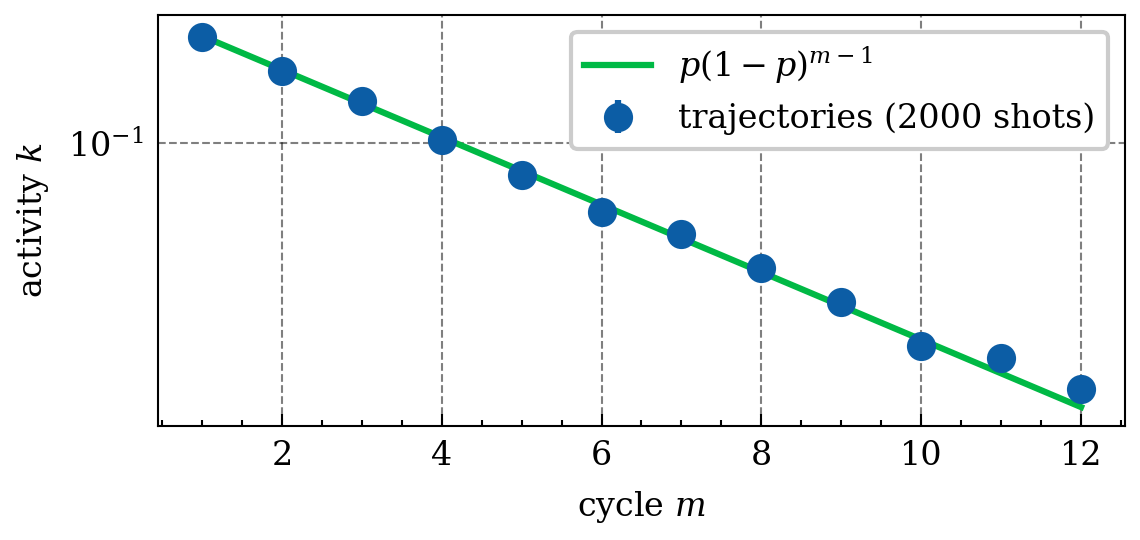

In [9]:
num_system, phi, num_cycles, num_shots = 3, 0.5, 12, 2000
system_sites, ancilla_sites, coupling_pairs = interleaved_collisional_layout(num_system)
num_sites = 2 * num_system

dqc = collisional_dqc([], ancilla_sites, coupling_pairs, phi, num_cycles, num_sites)
initial = Statevector(bitstring="10" * num_system)

rng = np.random.default_rng(42)
activities = np.zeros((num_shots, num_cycles))
for shot in range(num_shots):
    _, outcomes = dqc.run(initial, rng=rng)
    for cycle, outcome in enumerate(outcomes):
        activities[shot, cycle] = outcome.count("1") / num_system

probability = np.sin(phi) ** 2
cycles = np.arange(1, num_cycles + 1)
expected = probability * (1 - probability) ** (cycles - 1)
observed = activities.mean(axis=0)
sigma = np.sqrt(expected * (1 - expected) / (num_shots * num_system))

fig, ax = plt.subplots(figsize=(4, 2))
ax.errorbar(cycles, observed, yerr=sigma, fmt="o", label=f"trajectories ({num_shots} shots)")
ax.plot(cycles, expected, "-", label=r"$p(1-p)^{m-1}$")
ax.set_xlabel("cycle $m$")
ax.set_ylabel("activity $k$")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()

print("max deviation:", f"{np.max(np.abs(observed - expected) / sigma):.2f} sigma")

## 3. Trajectory ensemble vs the Lindblad equation

In the small-angle limit the protocol reproduces

$$\partial_t\rho = -i[H_S,\rho] + \Gamma\sum_i\left(\sigma^-_i\rho\,\sigma^+_i -
\tfrac{1}{2}\{n_i,\rho\}\right)$$

Integrating this directly is an independent check — it never touches the circuit code.

Three refinements of the *same* evolution: total time $T$ and rate $\Gamma = \phi^2/\delta t$ are
both held fixed, and only the step count changes. Every curve therefore spans the same window, so
their residuals are comparable; varying $\delta t$ at fixed cycle count instead would let the
finest curve cover the least time and flatter itself.

The residual should fall as $O(\delta t)$. It does **not** vanish at finite $\delta t$, and that
is expected rather than a bug: the correspondence only holds as $\delta t\to 0$.

In [5]:
def lindblad_occupation(num_system, omega, field_v, rate, times):
    """Average system occupation from direct integration of the Lindblad equation.

    Returns one value per entry of times; the initial state is all system qubits in |1>.
    """
    dim = 2**num_system

    def embed(factors):
        matrix = factors.get(0, IDENTITY)
        for site in range(1, num_system):
            matrix = np.kron(matrix, factors.get(site, IDENTITY))
        return matrix

    hamiltonian = sum(omega * embed({site: PAULI_X}) for site in range(num_system))
    for site in range(num_system - 1):
        hamiltonian = hamiltonian + field_v * embed({site: PAULI_Z, site + 1: PAULI_Z})

    jumps = [embed({site: LOWER}) for site in range(num_system)]
    numbers = [jump.conj().T @ jump for jump in jumps]
    total_number = sum(numbers)

    def rhs(_, flat):
        rho = flat.reshape(dim, dim)
        out = -1j * (hamiltonian @ rho - rho @ hamiltonian)
        for jump, number in zip(jumps, numbers):
            out += rate * (jump @ rho @ jump.conj().T - 0.5 * (number @ rho + rho @ number))
        return out.ravel()

    rho0 = np.zeros((dim, dim), dtype=complex)
    rho0[-1, -1] = 1.0
    solution = solve_ivp(rhs, (0.0, times[-1]), rho0.ravel(), t_eval=times, rtol=1e-9, atol=1e-11)
    return np.array(
        [np.trace(total_number @ y.reshape(dim, dim)).real / num_system for y in solution.y.T]
    )

total time fixed at T=2.0, rate fixed at 0.36
dt        max |trajectory - Lindblad|
1.0000    0.0554
0.2500    0.0173
0.0625    0.0067


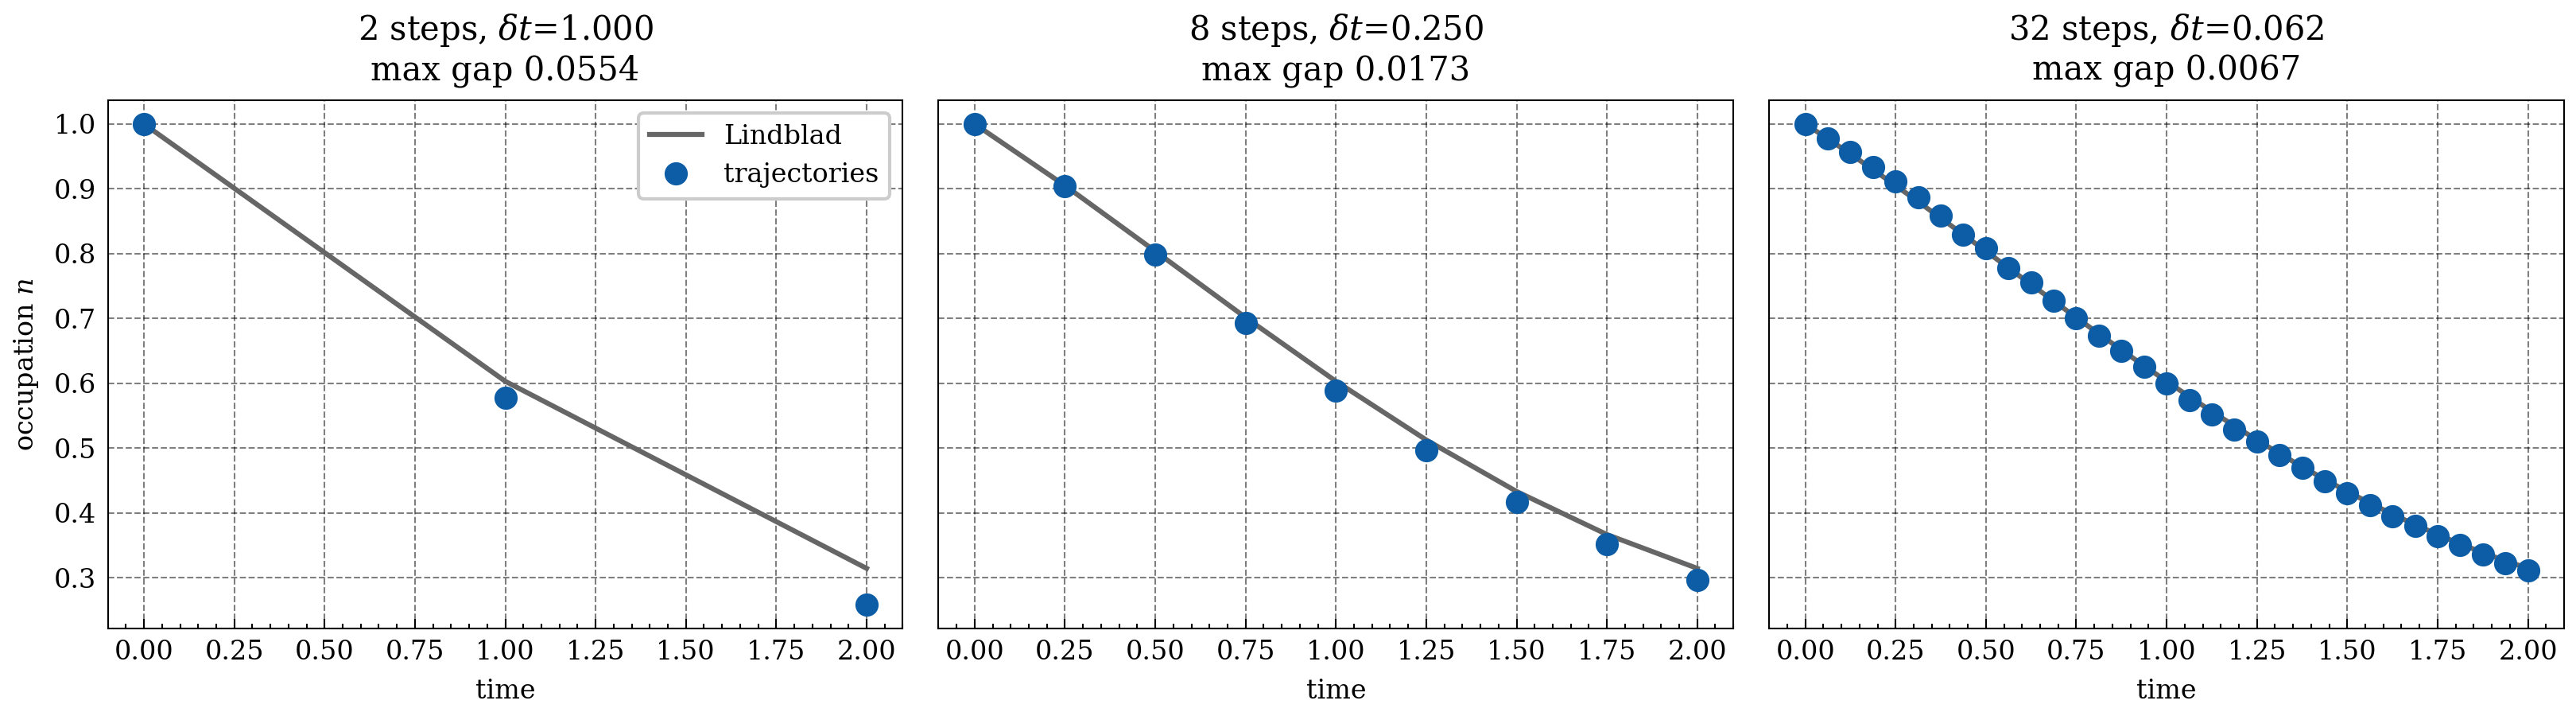

In [6]:
num_system, omega, field_v = 2, 0.4, 0.3
num_shots, rate, total_time = 2000, 0.36, 2.0
system_sites, ancilla_sites, coupling_pairs = interleaved_collisional_layout(num_system)
num_sites = 2 * num_system
system_number = NumberOperator(num_sites, qubits=system_sites)
initial = Statevector(bitstring="10" * num_system)

step_counts = [2, 8, 32]
fig, axes = plt.subplots(1, len(step_counts), figsize=(11, 3.2), sharey=True)
residuals = []
for ax, num_cycles in zip(axes, step_counts):
    dt = total_time / num_cycles
    phi = np.sqrt(rate * dt)
    layer = dissipative_ising_layer(system_sites, omega, field_v, dt)
    dqc = collisional_dqc(layer, ancilla_sites, coupling_pairs, phi, num_cycles, num_sites)

    rng = np.random.default_rng(0)
    totals = np.zeros(num_cycles)
    for shot in range(num_shots):
        occupation_trace.clear()
        dqc.run(initial, observer=record_occupation, rng=rng)
        totals += np.array(occupation_trace[:num_cycles])
    trajectory = np.concatenate([[1.0], totals / num_shots])

    times = np.arange(num_cycles + 1) * dt
    exact = lindblad_occupation(num_system, omega, field_v, rate, times)
    residuals.append((dt, np.max(np.abs(trajectory - exact))))

    ax.plot(times, exact, "-", color="0.4", label="Lindblad")
    ax.plot(times, trajectory, "o", color="C0", label="trajectories")
    ax.set_title(f"{num_cycles} steps, $\\delta t$={dt:.3f}\nmax gap {residuals[-1][1]:.4f}")
    ax.set_xlabel("time")

axes[0].set_ylabel("occupation $n$")
axes[0].legend()
plt.tight_layout()

print(f"total time fixed at T={total_time}, rate fixed at {rate}")
print("dt        max |trajectory - Lindblad|")
for dt, residual in residuals:
    print(f"{dt:<9.4f} {residual:.4f}")

## 4. Both observables, both models

`observer` fires *after* each round, so index $i$ is the state at $t=(i+1)\delta t$, and the last
round adds no evolution. Occupation at $t=0$ is prepended rather than read from the observer.

Occupation $n(t_m)$ over the system register, activity $k(t_m)$ from the measurement record —
the two quantities the source document plots. Same protocol, same $\phi$; only $H_S$ differs.

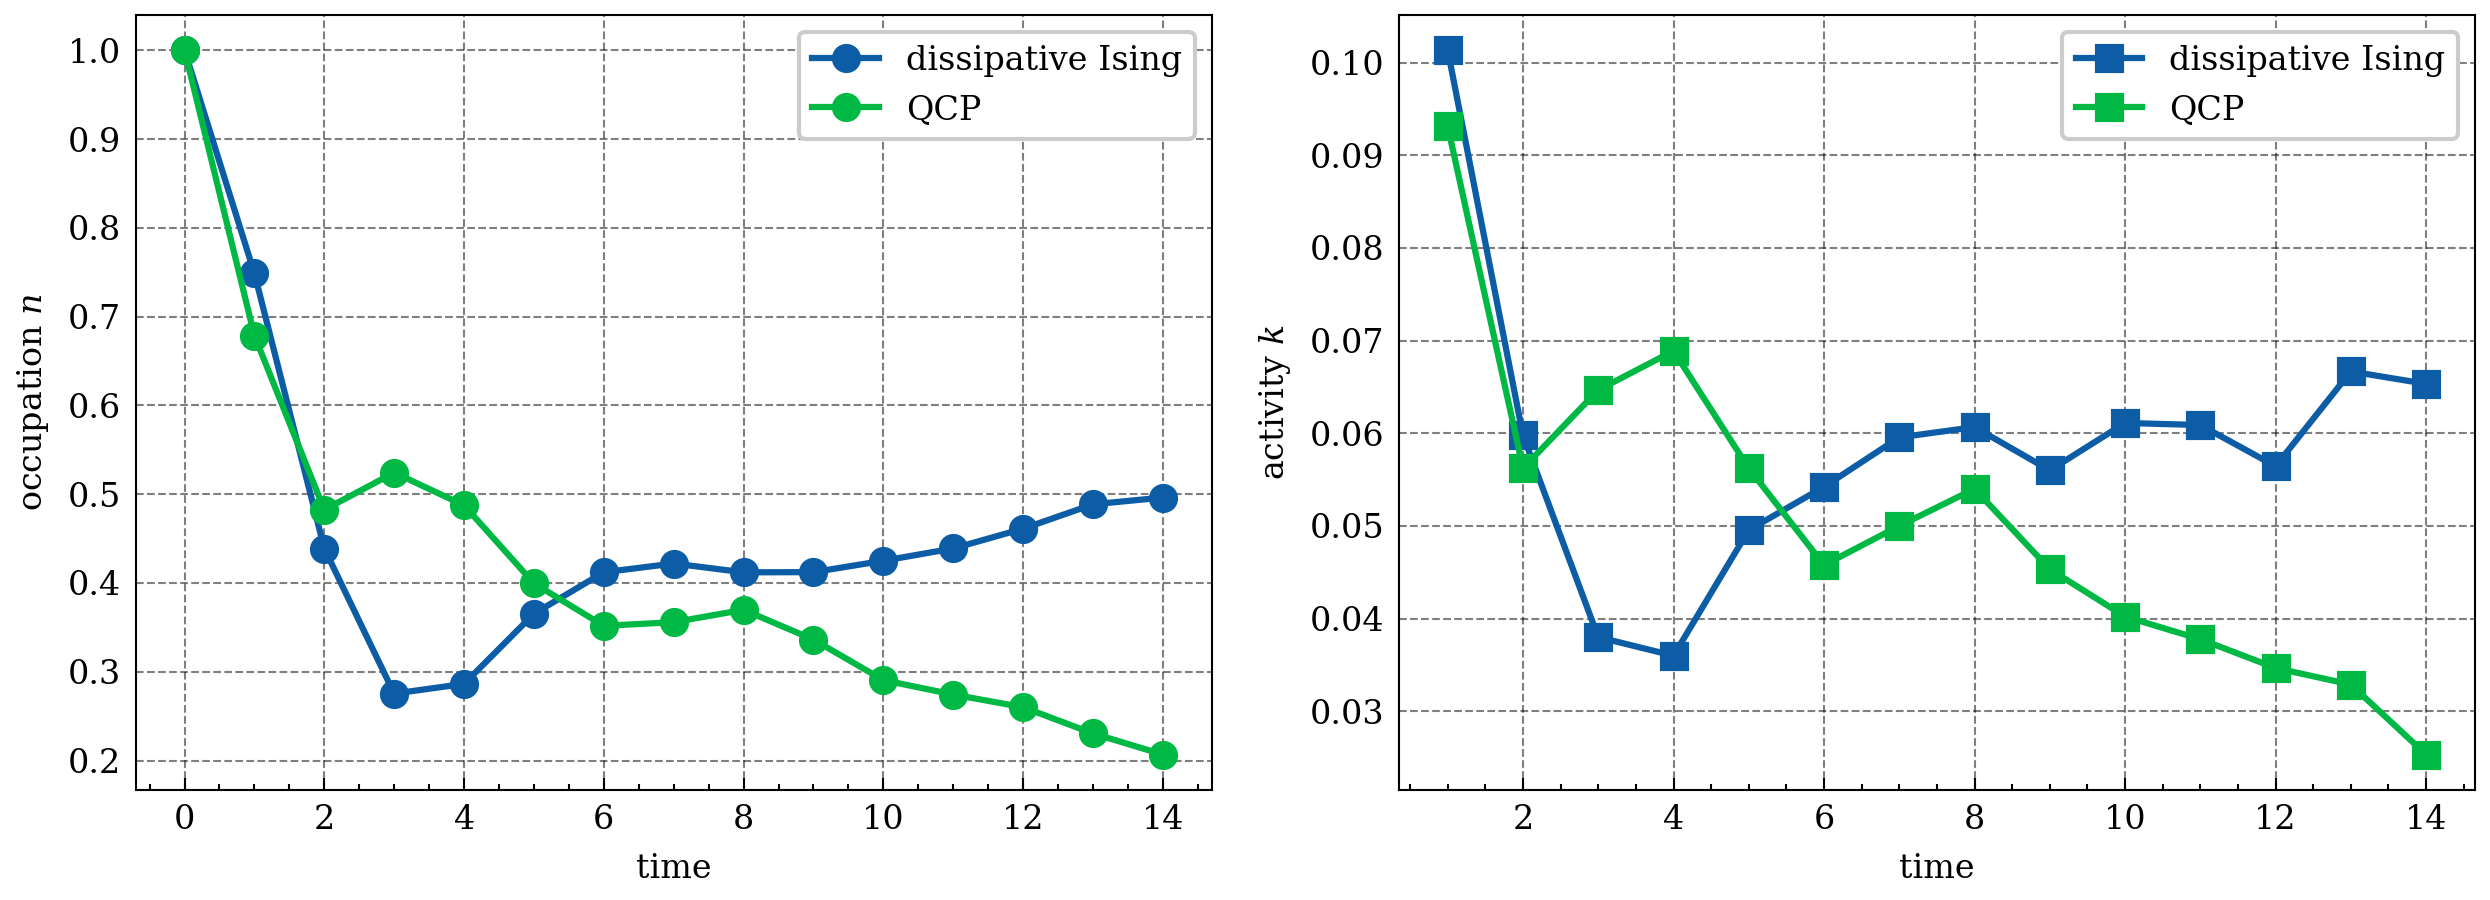

In [7]:
num_system, phi, num_cycles, num_shots, dt = 3, 0.35, 14, 1500, 1.0
system_sites, ancilla_sites, coupling_pairs = interleaved_collisional_layout(num_system)
num_sites = 2 * num_system
system_number = NumberOperator(num_sites, qubits=system_sites)
initial = Statevector(bitstring="10" * num_system)

models = {
    "dissipative Ising": dissipative_ising_layer(system_sites, 0.4, 0.3, dt),
    "QCP": qcp_layer(system_sites, 0.8, dt),
}

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.2))
for label, layer in models.items():
    dqc = collisional_dqc(layer, ancilla_sites, coupling_pairs, phi, num_cycles, num_sites)

    rng = np.random.default_rng(7)
    occupation = np.zeros(num_cycles)
    activity = np.zeros(num_cycles)
    for shot in range(num_shots):
        occupation_trace.clear()
        _, outcomes = dqc.run(initial, observer=record_occupation, rng=rng)
        occupation += np.array(occupation_trace[:num_cycles])
        activity += np.array([o.count("1") / num_system for o in outcomes])

    occupation = np.concatenate([[1.0], occupation / num_shots])
    axes[0].plot(np.arange(num_cycles + 1) * dt, occupation, "o-", label=label)
    axes[1].plot(np.arange(1, num_cycles + 1) * dt, activity / num_shots, "s-", label=label)

axes[0].set_xlabel("time"); axes[0].set_ylabel("occupation $n$"); axes[0].legend()
axes[1].set_xlabel("time"); axes[1].set_ylabel("activity $k$"); axes[1].legend()
plt.tight_layout()

## 5. Absorbing state

$H_{SA}|00\rangle = 0$, so once every system qubit reaches $|0\rangle$ nothing further happens.
At large $\phi$ and with $\Omega = 0$ there is no drive back out, so the state converges to
$|0\ldots0\rangle$ and both observables go to zero.

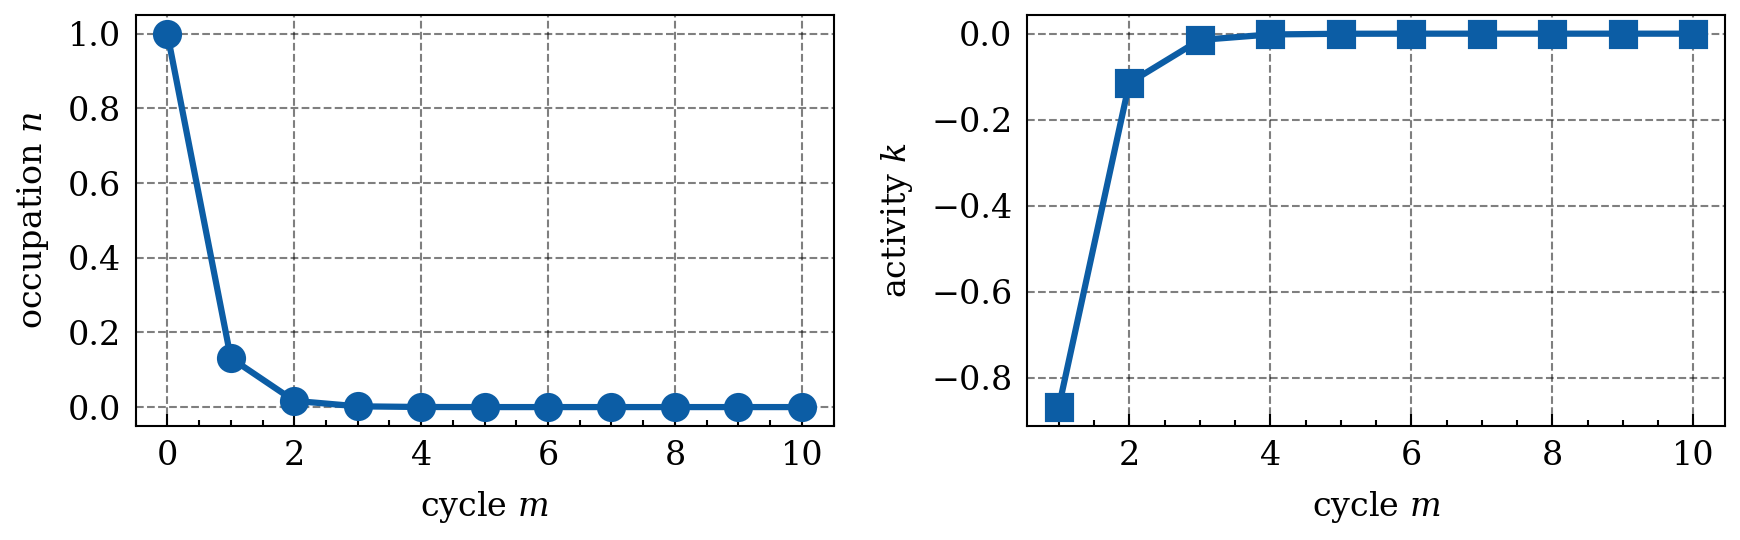

In [11]:
num_system, phi, num_cycles, num_shots = 3, 1.2, 10, 600
system_sites, ancilla_sites, coupling_pairs = interleaved_collisional_layout(num_system)
num_sites = 2 * num_system
system_number = NumberOperator(num_sites, qubits=system_sites)
initial = Statevector(bitstring="10" * num_system)

dqc = collisional_dqc([], ancilla_sites, coupling_pairs, phi, num_cycles, num_sites)

rng = np.random.default_rng(3)
occupation = np.zeros(num_cycles)
ground_weight = 0.0
for shot in range(num_shots):
    occupation_trace.clear()
    final, _ = dqc.run(initial, observer=record_occupation, rng=rng)
    occupation += np.array(occupation_trace[:num_cycles])
    ground_weight += abs(final.to_array()[0]) ** 2

occupation = np.concatenate([[1.0], occupation / num_shots])

fig, axes = plt.subplots(1, 2, figsize=(6,2))
axes[0].plot(np.arange(num_cycles + 1), occupation, "o-")
axes[0].set_xlabel("cycle $m$"); axes[0].set_ylabel("occupation $n$")
axes[1].plot(np.arange(1, num_cycles + 1), occupation[1:] - occupation[:-1], "s-")
axes[1].set_xlabel("cycle $m$"); axes[1].set_ylabel("activity $k$")
plt.tight_layout()